We begin by loading the training, testing and sample submission datasets using Pandas. We inspect their dimensions, column names, data types and initial records to understand the structure and verify that the datasets have loaded correctly.

In [1]:
import pandas as pd
import numpy as np

# Load datasets
train = pd.read_csv('/content/dataset_B_training.csv')
test = pd.read_csv('/content/dataset_B_testing.csv')
sample_submission = pd.read_csv(
    '/content/dataset_B_example_submission.csv'
)

# Inspect dataset dimensions
print("Training shape:", train.shape)
print("Testing shape:", test.shape)
print("Submission shape:", sample_submission.shape)

# Inspect initial records
display(train.head())

# Inspect data types and missing values
display(train.info())

# Check target distribution
display(train['h1n1_vaccine'].value_counts(normalize=True))

Training shape: (4756, 31)
Testing shape: (4749, 30)
Submission shape: (4749, 2)


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,h1n1_vaccine
0,1,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",2.0,1.0,science,0,0
1,2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Below Poverty,Not Married,Own,Employed,Non-MSA,0.0,3.0,wholesale,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"> $75,000",Not Married,Own,Employed,"MSA, Principle City",0.0,0.0,education,0,1
3,4,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Not Married,Rent,Not in Labor Force,Non-MSA,0.0,0.0,NaN,0,0
4,5,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,Not Married,NaN,Unemployed,Non-MSA,3.0,0.0,NaN,0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   h1n1_concern                   4741 non-null   float64
 2   h1n1_knowledge                 4734 non-null   float64
 3   behavioral_antiviral_meds      4739 non-null   float64
 4   behavioral_avoidance           4729 non-null   float64
 5   behavioral_face_mask           4752 non-null   float64
 6   behavioral_wash_hands          4748 non-null   float64
 7   behavioral_large_gatherings    4747 non-null   float64
 8   behavioral_outside_home        4741 non-null   float64
 9   behavioral_touch_face          4736 non-null   float64
 10  doctor_recc_h1n1               4437 non-null   float64
 11  child_under_6_months           4622 non-null   float64
 12  health_worker                  4625 non-null   f

None

,proportion
h1n1_vaccine,
0,0.605971
1,0.394029


**Exploratory Data Analysis (EDA)**

Missing value analysis

In [3]:
# Calculate missing values
missing_analysis = pd.DataFrame({
    'Missing_Count': train.isnull().sum(),
    'Missing_Percentage': train.isnull().mean() * 100
})

missing_analysis = missing_analysis.sort_values(
    by='Missing_Percentage',
    ascending=False
)

display(missing_analysis[missing_analysis['Missing_Count'] > 0])

,Missing_Count,Missing_Percentage
employment_sector,2364,49.705635
health_insurance,1925,40.475189
income_poverty,712,14.970563
doctor_recc_h1n1,319,6.707317
rent_or_own,315,6.623213
employment_status,235,4.941127
marital_status,226,4.751892
education,224,4.709840
child_under_6_months,134,2.817494
health_worker,131,2.754415


Visualise missing values

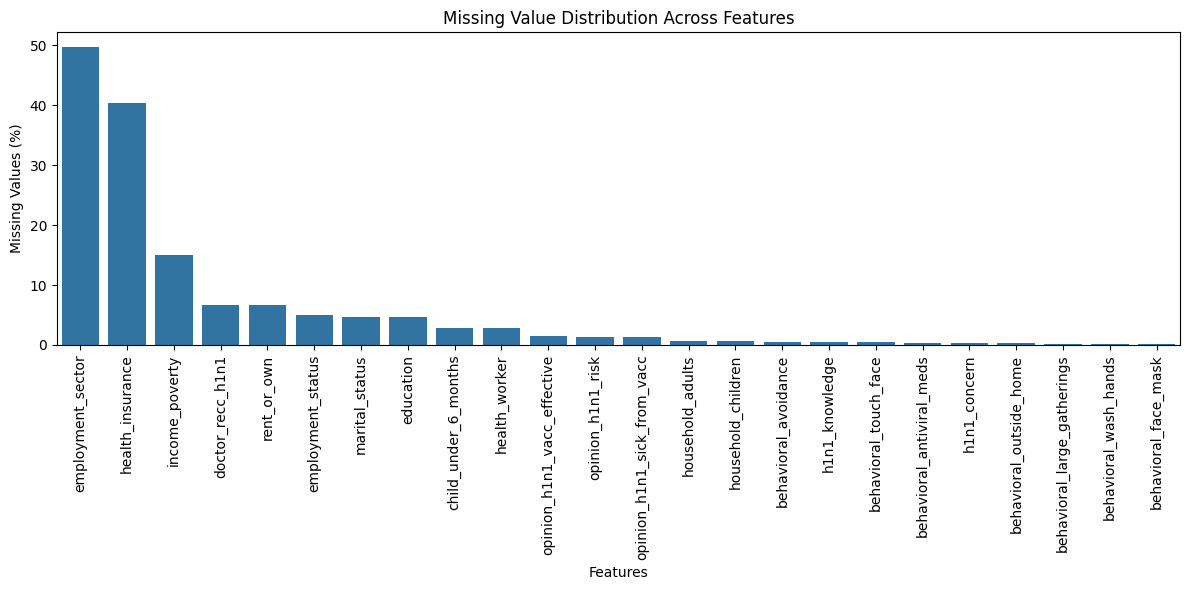

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

missing_data = missing_analysis[
    missing_analysis['Missing_Count'] > 0
]

plt.figure(figsize=(12, 6))

sns.barplot(
    x=missing_data.index,
    y=missing_data['Missing_Percentage']
)

plt.xticks(rotation=90)
plt.ylabel('Missing Values (%)')
plt.xlabel('Features')
plt.title('Missing Value Distribution Across Features')
plt.tight_layout()
plt.show()

Analyse the target variable

Vaccination counts:
h1n1_vaccine
0    2882
1    1874
Name: count, dtype: int64

Vaccination percentages:
h1n1_vaccine
0    60.59714
1    39.40286
Name: proportion, dtype: float64


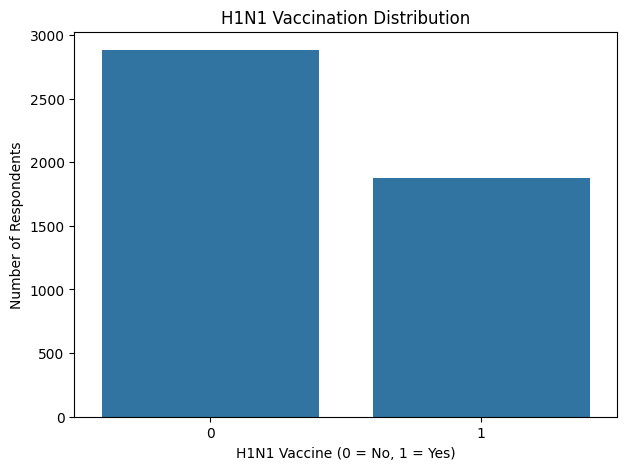

In [7]:
# Count vaccinated and unvaccinated respondents
target_counts = train['h1n1_vaccine'].value_counts()

print("Vaccination counts:")
print(target_counts)

print("\nVaccination percentages:")
print(train['h1n1_vaccine'].value_counts(normalize=True) * 100)

# Visualise target distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=train,
    x='h1n1_vaccine'
)

plt.title('H1N1 Vaccination Distribution')
plt.xlabel('H1N1 Vaccine (0 = No, 1 = Yes)')
plt.ylabel('Number of Respondents')

plt.show()


Analyse feature relationships

Vaccination rate by doctor recommendation:
doctor_recc_h1n1
0.0    27.913623
1.0    72.748447
Name: h1n1_vaccine, dtype: float64


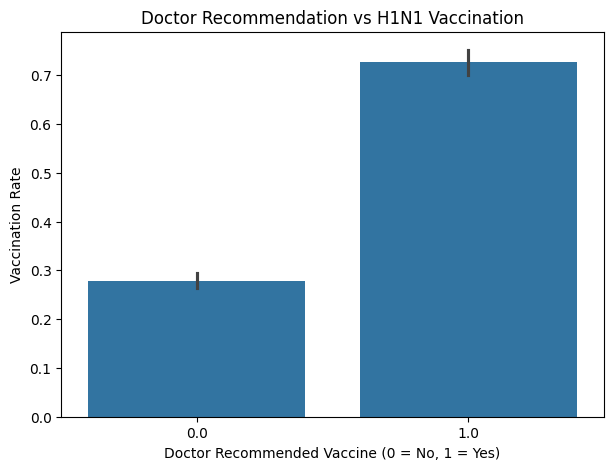

In [8]:
# Vaccination rate by doctor recommendation

doctor_analysis = train.groupby(
    'doctor_recc_h1n1'
)['h1n1_vaccine'].mean() * 100

print("Vaccination rate by doctor recommendation:")
print(doctor_analysis)

# Visualisation
plt.figure(figsize=(7, 5))

sns.barplot(
    data=train,
    x='doctor_recc_h1n1',
    y='h1n1_vaccine'
)

plt.title('Doctor Recommendation vs H1N1 Vaccination')
plt.xlabel('Doctor Recommended Vaccine (0 = No, 1 = Yes)')
plt.ylabel('Vaccination Rate')

plt.show()

Analyse the effect of chronic medical conditions

,mean,count,vaccination_rate
number_chronic_med_conditions,,,
0,0.359795,3313,35.979475
1,0.456014,1114,45.601436
2,0.513725,255,51.372549
3,0.596774,62,59.677419
4,0.400000,10,40.000000
5,1.000000,1,100.000000
6,1.000000,1,100.000000


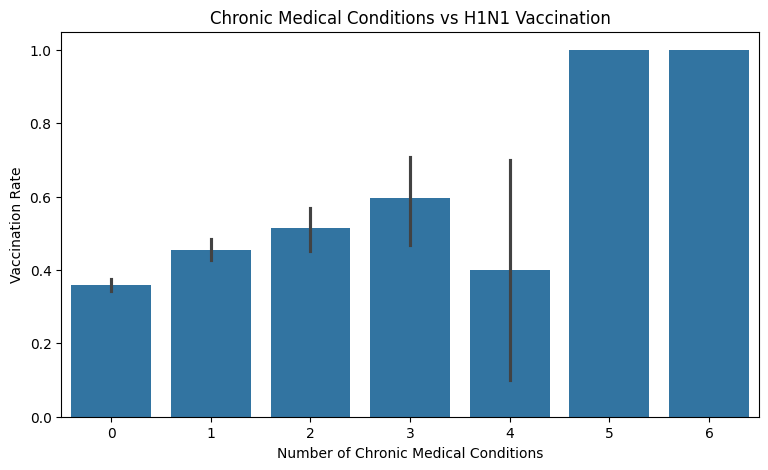

In [9]:
# Vaccination rate by number of chronic conditions

chronic_analysis = train.groupby(
    'number_chronic_med_conditions'
)['h1n1_vaccine'].agg(['mean', 'count'])

chronic_analysis['vaccination_rate'] = (
    chronic_analysis['mean'] * 100
)

display(chronic_analysis)

# Visualisation
plt.figure(figsize=(9, 5))

sns.barplot(
    data=train,
    x='number_chronic_med_conditions',
    y='h1n1_vaccine'
)

plt.title(
    'Chronic Medical Conditions vs H1N1 Vaccination'
)

plt.xlabel('Number of Chronic Medical Conditions')
plt.ylabel('Vaccination Rate')

plt.show()

Analyse vaccination by age group

,mean,count,vaccination_rate
age_group,,,
18 - 34 Years,0.364653,894,36.465324
35 - 44 Years,0.396055,659,39.605463
45 - 54 Years,0.365827,913,36.582694
55 - 64 Years,0.418779,1065,41.877934
65+ Years,0.413878,1225,41.387755


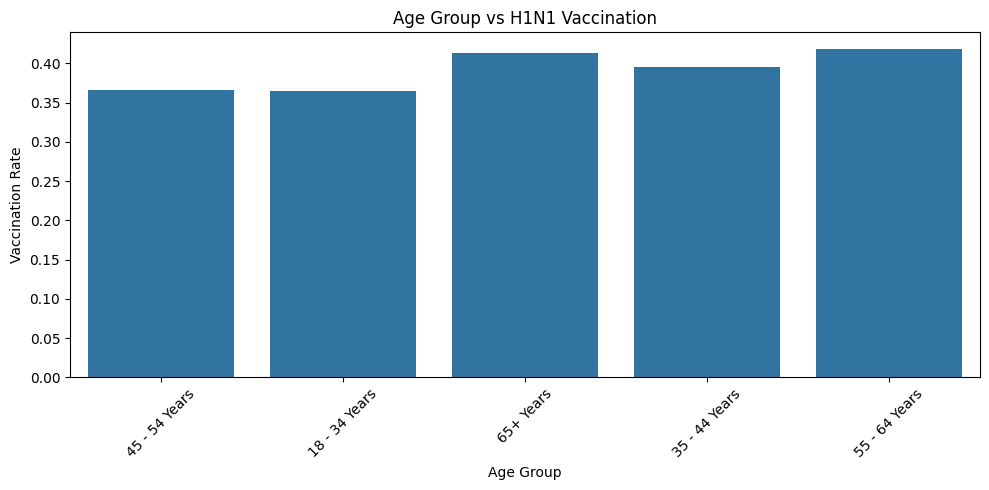

In [10]:
# Vaccination rate by age group

age_analysis = train.groupby(
    'age_group'
)['h1n1_vaccine'].agg(['mean', 'count'])

age_analysis['vaccination_rate'] = (
    age_analysis['mean'] * 100
)

display(age_analysis)

# Visualisation
plt.figure(figsize=(10, 5))

sns.barplot(
    data=train,
    x='age_group',
    y='h1n1_vaccine',
    errorbar=None
)

plt.title('Age Group vs H1N1 Vaccination')
plt.xlabel('Age Group')
plt.ylabel('Vaccination Rate')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Analyse vaccination by H1N1 concern

,mean,count,vaccination_rate
h1n1_concern,,,
0.0,0.295019,522,29.501916
1.0,0.325036,1406,32.503556
2.0,0.420707,1980,42.070707
3.0,0.509004,833,50.900360


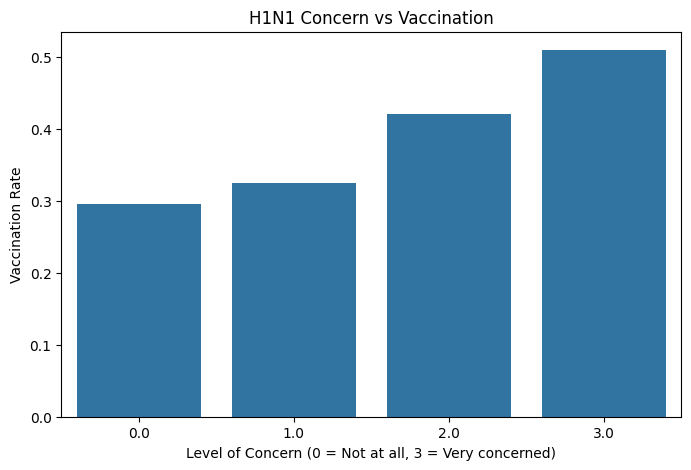

In [11]:
# Vaccination rate by H1N1 concern

concern_analysis = train.groupby(
    'h1n1_concern'
)['h1n1_vaccine'].agg(['mean', 'count'])

concern_analysis['vaccination_rate'] = (
    concern_analysis['mean'] * 100
)

display(concern_analysis)

# Visualisation
plt.figure(figsize=(8, 5))

sns.barplot(
    data=train,
    x='h1n1_concern',
    y='h1n1_vaccine',
    errorbar=None
)

plt.title('H1N1 Concern vs Vaccination')
plt.xlabel('Level of Concern (0 = Not at all, 3 = Very concerned)')
plt.ylabel('Vaccination Rate')

plt.show()

Analyse H1N1 knowledge

,mean,count,vaccination_rate
h1n1_knowledge,,,
0.0,0.272727,385,27.272727
1.0,0.347410,2510,34.741036
2.0,0.483415,1839,48.341490


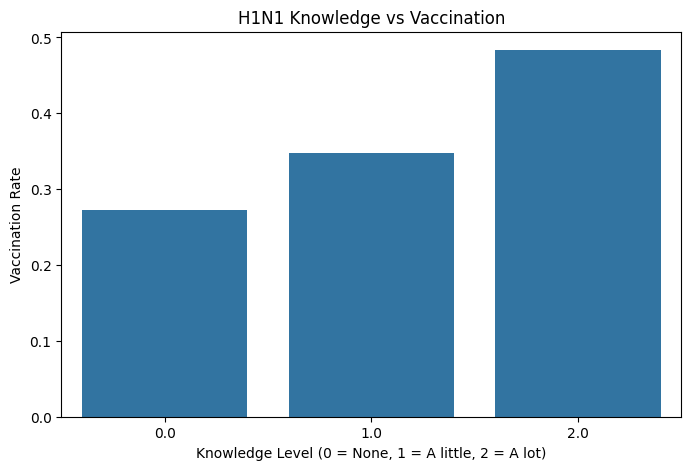

In [12]:
# Vaccination rate by H1N1 knowledge

knowledge_analysis = train.groupby(
    'h1n1_knowledge'
)['h1n1_vaccine'].agg(['mean', 'count'])

knowledge_analysis['vaccination_rate'] = (
    knowledge_analysis['mean'] * 100
)

display(knowledge_analysis)

# Visualisation
plt.figure(figsize=(8, 5))

sns.barplot(
    data=train,
    x='h1n1_knowledge',
    y='h1n1_vaccine',
    errorbar=None
)

plt.title('H1N1 Knowledge vs Vaccination')
plt.xlabel('Knowledge Level (0 = None, 1 = A little, 2 = A lot)')
plt.ylabel('Vaccination Rate')

plt.show()

**Prepare the data for machine learning**

Separate features and target:

Before training a classification model, we separate the independent variables (features) from the dependent variable (target).

Our target is h1n1_vaccine, representing whether a respondent received the vaccine.



In [13]:
# Separate input features and target variable

X = train.drop(
    columns=['respondent_id', 'h1n1_vaccine']
)

y = train['h1n1_vaccine']

# Prepare test features
X_test = test.drop(
    columns=['respondent_id']
)

# Check dimensions
print("Training features:", X.shape)
print("Target:", y.shape)
print("Testing features:", X_test.shape)

# Verify target distribution
print("\nTarget distribution:")
print(y.value_counts())

Training features: (4756, 29)
Target: (4756,)
Testing features: (4749, 29)

Target distribution:
h1n1_vaccine
0    2882
1    1874
Name: count, dtype: int64


Split the data into training and validation sets

In [14]:
from sklearn.model_selection import train_test_split

# Split dataset into 80% training and 20% validation
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Check dataset dimensions
print("Training features:", X_train.shape)
print("Validation features:", X_valid.shape)

print("Training target:", y_train.shape)
print("Validation target:", y_valid.shape)

# Check class distribution
print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nValidation class distribution:")
print(y_valid.value_counts(normalize=True) * 100)

Training features: (3804, 29)
Validation features: (952, 29)
Training target: (3804,)
Validation target: (952,)

Training class distribution:
h1n1_vaccine
0    60.594111
1    39.405889
Name: proportion, dtype: float64

Validation class distribution:
h1n1_vaccine
0    60.609244
1    39.390756
Name: proportion, dtype: float64


Identify numerical and categorical features

In [15]:
# Identify numerical features
numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Identify categorical features
categorical_features = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

# Display results
print("Number of numerical features:", len(numerical_features))
print("Numerical features:")
print(numerical_features)

print("\nNumber of categorical features:", len(categorical_features))
print("Categorical features:")
print(categorical_features)

# Verify that all features are accounted for
print("\nTotal features:",
      len(numerical_features) + len(categorical_features))

Number of numerical features: 19
Numerical features:
['h1n1_concern', 'h1n1_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'doctor_recc_h1n1', 'child_under_6_months', 'health_worker', 'health_insurance', 'opinion_h1n1_vacc_effective', 'opinion_h1n1_risk', 'opinion_h1n1_sick_from_vacc', 'household_adults', 'household_children', 'number_chronic_med_conditions']

Number of categorical features: 10
Categorical features:
['age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'employment_sector']

Total features: 29


Handle missing values and encode categorical features

In [16]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Preprocessing for numerical features
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Preprocessing for categorical features
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


**Train a Logistic Regression model**

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create Logistic Regression pipeline
logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

# Make predictions on validation data
y_pred_logistic = logistic_model.predict(X_valid)

# Predict vaccination probabilities
y_prob_logistic = logistic_model.predict_proba(X_valid)[:, 1]

print("Logistic Regression model trained successfully!")

print("\nFirst 10 predictions:")
print(y_pred_logistic[:10])

print("\nFirst 10 vaccination probabilities:")
print(y_prob_logistic[:10])

Logistic Regression model trained successfully!

First 10 predictions:
[0 1 0 0 0 0 0 0 1 0]

First 10 vaccination probabilities:
[0.31755271 0.57909686 0.08203885 0.10911787 0.04577781 0.17286162
 0.11026438 0.33748259 0.61078033 0.04934016]


Evaluate the Logistic Regression model

In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_valid, y_pred_logistic)
precision = precision_score(y_valid, y_pred_logistic)
recall = recall_score(y_valid, y_pred_logistic)
f1 = f1_score(y_valid, y_pred_logistic)
auc = roc_auc_score(y_valid, y_prob_logistic)

# Display results
print("Logistic Regression Performance")
print("--------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_valid, y_pred_logistic))

Logistic Regression Performance
--------------------------------
Accuracy:  0.7605
Precision: 0.7290
Recall:    0.6240
F1 Score:  0.6724
ROC-AUC:   0.8164

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.85      0.81       577
           1       0.73      0.62      0.67       375

    accuracy                           0.76       952
   macro avg       0.75      0.74      0.74       952
weighted avg       0.76      0.76      0.76       952



Train a Random Forest model

In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create Random Forest pipeline
random_forest_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

# Train Random Forest
random_forest_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = random_forest_model.predict(X_valid)

# Predict probabilities
y_prob_rf = random_forest_model.predict_proba(X_valid)[:, 1]

print("Random Forest model trained successfully!")

print("\nFirst 10 predictions:")
print(y_pred_rf[:10])

print("\nFirst 10 vaccination probabilities:")
print(y_prob_rf[:10])

Random Forest model trained successfully!

First 10 predictions:
[0 0 0 0 0 0 0 0 1 0]

First 10 vaccination probabilities:
[0.44065545 0.41417577 0.19196074 0.15484701 0.13984594 0.15472193
 0.09982526 0.34508403 0.59377378 0.09866681]


Evaluate Random Forest :

We will evaluate Random Forest using the same five metrics used for Logistic Regression:
- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC

In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Calculate Random Forest evaluation metrics
rf_accuracy = accuracy_score(y_valid, y_pred_rf)
rf_precision = precision_score(y_valid, y_pred_rf)
rf_recall = recall_score(y_valid, y_pred_rf)
rf_f1 = f1_score(y_valid, y_pred_rf)
rf_auc = roc_auc_score(y_valid, y_prob_rf)

# Display results
print("Random Forest Performance")
print("--------------------------------")
print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1 Score:  {rf_f1:.4f}")
print(f"ROC-AUC:   {rf_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_valid, y_pred_rf))

Random Forest Performance
--------------------------------
Accuracy:  0.7584
Precision: 0.7377
Recall:    0.6000
F1 Score:  0.6618
ROC-AUC:   0.8022

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.86      0.81       577
           1       0.74      0.60      0.66       375

    accuracy                           0.76       952
   macro avg       0.75      0.73      0.74       952
weighted avg       0.76      0.76      0.75       952



Create a model comparison table

In [21]:
# Compare model performance

comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [accuracy, rf_accuracy],
    'Precision': [precision, rf_precision],
    'Recall': [recall, rf_recall],
    'F1 Score': [f1, rf_f1],
    'ROC-AUC': [auc, rf_auc]
})

comparison = comparison.sort_values(
    by='ROC-AUC',
    ascending=False
)

display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7605,0.7290,0.624,0.6724,0.8164
1,Random Forest,0.7584,0.7377,0.600,0.6618,0.8022


Train CatBoost

In [22]:
# Install CatBoost
!pip -q install catboost

from catboost import CatBoostClassifier
from sklearn.pipeline import Pipeline

# Create CatBoost pipeline
catboost_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', CatBoostClassifier(
        iterations=500,
        depth=6,
        learning_rate=0.05,
        loss_function='Logloss',
        random_seed=42,
        verbose=False
    ))
])

# Train the model
catboost_model.fit(X_train, y_train)

# Predict vaccination status
y_pred_catboost = catboost_model.predict(X_valid)

# Predict vaccination probabilities
y_prob_catboost = catboost_model.predict_proba(X_valid)[:, 1]

print("CatBoost model trained successfully!")

print("\nFirst 10 predictions:")
print(y_pred_catboost[:10])

print("\nFirst 10 probabilities:")
print(y_prob_catboost[:10])

CatBoost model trained successfully!

First 10 predictions:
[0 1 0 0 0 0 0 0 1 0]

First 10 probabilities:
[0.4310097  0.74542719 0.10430293 0.13101076 0.03609386 0.09434247
 0.04036756 0.20701279 0.79267975 0.04250592]


Evaluate the CatBoost model

In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Calculate CatBoost evaluation metrics
cat_accuracy = accuracy_score(y_valid, y_pred_catboost)
cat_precision = precision_score(y_valid, y_pred_catboost)
cat_recall = recall_score(y_valid, y_pred_catboost)
cat_f1 = f1_score(y_valid, y_pred_catboost)
cat_auc = roc_auc_score(y_valid, y_prob_catboost)

# Display results
print("CatBoost Performance")
print("--------------------------------")
print(f"Accuracy:  {cat_accuracy:.4f}")
print(f"Precision: {cat_precision:.4f}")
print(f"Recall:    {cat_recall:.4f}")
print(f"F1 Score:  {cat_f1:.4f}")
print(f"ROC-AUC:   {cat_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_valid, y_pred_catboost))

CatBoost Performance
--------------------------------
Accuracy:  0.7563
Precision: 0.7097
Recall:    0.6453
F1 Score:  0.6760
ROC-AUC:   0.8061

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.83      0.80       577
           1       0.71      0.65      0.68       375

    accuracy                           0.76       952
   macro avg       0.75      0.74      0.74       952
weighted avg       0.75      0.76      0.75       952



Compare all three models

In [24]:
# Compare all three machine learning models

model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'CatBoost'
    ],
    'Accuracy': [
        accuracy, rf_accuracy, cat_accuracy
    ],
    'Precision': [
        precision, rf_precision, cat_precision
    ],
    'Recall': [
        recall, rf_recall, cat_recall
    ],
    'F1 Score': [
        f1, rf_f1, cat_f1
    ],
    'ROC-AUC': [
        auc, rf_auc, cat_auc
    ]
})

model_comparison = model_comparison.sort_values(
    by='ROC-AUC',
    ascending=False
)

display(model_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7605,0.7290,0.6240,0.6724,0.8164
2,CatBoost,0.7563,0.7097,0.6453,0.6760,0.8061
1,Random Forest,0.7584,0.7377,0.6000,0.6618,0.8022


**Hyperparameter tuning for Logistic Regression**

Hyperparameter tuning involves testing different model settings to find the combination that performs best.

For Logistic Regression, we'll tune:
- C: Controls regularisation strength.
- class_weight: Controls how the model weights the two classes.
- solver: The algorithm used to fit the model.
We'll use 5-fold cross-validation, which evaluates each configuration across five different training subsets rather than relying on a single split.

In [25]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create model pipeline
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=3000,
        random_state=42
    ))
])

# Define hyperparameters
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__class_weight': [None, 'balanced'],
    'classifier__solver': ['lbfgs', 'liblinear']
}

# Configure grid search
grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

# Train using training data only
grid_search.fit(X_train, y_train)

# Display best results
print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation ROC-AUC:")
print(round(grid_search.best_score_, 4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters:
{'classifier__C': 0.1, 'classifier__class_weight': None, 'classifier__solver': 'lbfgs'}

Best cross-validation ROC-AUC:
0.8235


### Logistic Regression Hyperparameter Tuning Results

GridSearchCV evaluated 20 hyperparameter configurations using five-fold cross-validation, resulting in 100 model fits.

The best configuration used a regularisation parameter of C = 0.1, no class weighting and the lbfgs solver.

This configuration achieved a mean cross-validation ROC-AUC of 0.8235.

The results suggest that stronger regularisation may improve model generalisation. The tuned model will now be evaluated on the held-out validation dataset to assess its performance against the original Logistic Regression baseline.

Evaluate the tuned Logistic Regression model

In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Retrieve the best model from GridSearchCV
tuned_lr = grid_search.best_estimator_

# Predict on the held-out validation dataset
y_pred_tuned = tuned_lr.predict(X_valid)

# Predict vaccination probabilities
y_prob_tuned = tuned_lr.predict_proba(X_valid)[:, 1]

# Calculate evaluation metrics
tuned_accuracy = accuracy_score(y_valid, y_pred_tuned)
tuned_precision = precision_score(y_valid, y_pred_tuned)
tuned_recall = recall_score(y_valid, y_pred_tuned)
tuned_f1 = f1_score(y_valid, y_pred_tuned)
tuned_auc = roc_auc_score(y_valid, y_prob_tuned)

# Compare original and tuned models
tuning_comparison = pd.DataFrame({
    'Model': [
        'Original Logistic Regression',
        'Tuned Logistic Regression'
    ],
    'Accuracy': [accuracy, tuned_accuracy],
    'Precision': [precision, tuned_precision],
    'Recall': [recall, tuned_recall],
    'F1 Score': [f1, tuned_f1],
    'ROC-AUC': [auc, tuned_auc]
})

display(tuning_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Original Logistic Regression,0.7605,0.729,0.6240,0.6724,0.8164
1,Tuned Logistic Regression,0.7574,0.725,0.6187,0.6676,0.8145


### Hyperparameter Tuning Evaluation

The tuned Logistic Regression model achieved a validation ROC-AUC of 0.8145, compared with 0.8164 for the original model.

The original model also achieved slightly higher accuracy, precision, recall and F1-score.

Although the tuned configuration achieved a cross-validation ROC-AUC of 0.8235, this improvement did not translate into better performance on the held-out validation dataset.

Therefore, the original Logistic Regression model was retained as the preferred candidate for subsequent analysis.

Visualise model performance using ROC curves

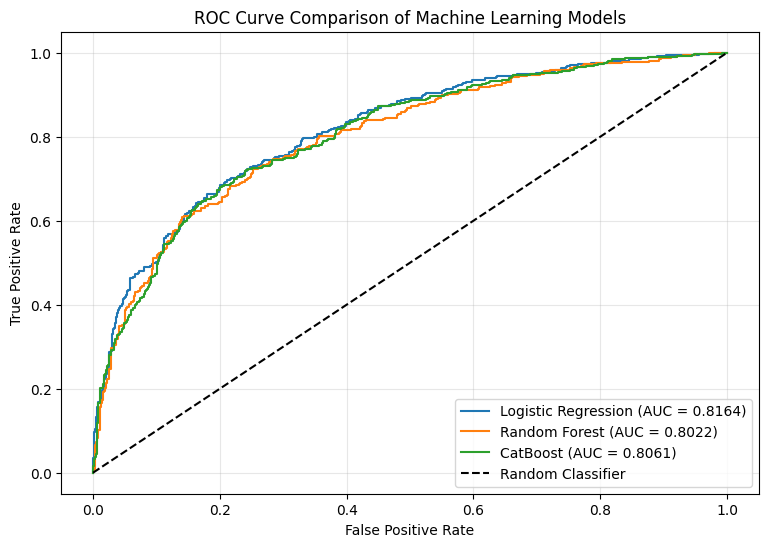

In [27]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

models = {
    "Logistic Regression": y_prob_logistic,
    "Random Forest": y_prob_rf,
    "CatBoost": y_prob_catboost
}

for name, probabilities in models.items():

    fpr, tpr, thresholds = roc_curve(
        y_valid,
        probabilities
    )

    auc_score = roc_auc_score(
        y_valid,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.4f})"
    )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    'k--',
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison of Machine Learning Models")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.show()

Explore hospitalisation risk factors

In [28]:
# Examine chronic medical conditions in the dataset

chronic_summary = (
    train['number_chronic_med_conditions']
    .value_counts(dropna=False)
    .sort_index()
)

print("Distribution of chronic medical conditions:")
print(chronic_summary)

print("\nPercentage distribution:")
print(
    train['number_chronic_med_conditions']
    .value_counts(normalize=True, dropna=False)
    .sort_index() * 100
)

Distribution of chronic medical conditions:
number_chronic_med_conditions
0    3313
1    1114
2     255
3      62
4      10
5       1
6       1
Name: count, dtype: int64

Percentage distribution:
number_chronic_med_conditions
0    69.659378
1    23.423045
2     5.361648
3     1.303616
4     0.210261
5     0.021026
6     0.021026
Name: proportion, dtype: float64


Calculate the vaccination break-even risk

In [29]:
# Vaccine and hospitalisation costs
vaccine_cost = 500
hospital_cost = 25000

# Illustrative vaccine effectiveness assumptions
effectiveness_values = [1.0, 0.8, 0.6, 0.4]

print("Vaccination break-even analysis")
print("--------------------------------")

for effectiveness in effectiveness_values:

    break_even_risk = (
        vaccine_cost /
        (hospital_cost * effectiveness)
    )

    print(
        f"Effectiveness: {effectiveness:.0%} | "
        f"Break-even risk: {break_even_risk:.2%}"
    )

Vaccination break-even analysis
--------------------------------
Effectiveness: 100% | Break-even risk: 2.00%
Effectiveness: 80% | Break-even risk: 2.50%
Effectiveness: 60% | Break-even risk: 3.33%
Effectiveness: 40% | Break-even risk: 5.00%


Create a hospitalisation risk scenario model

In [30]:
# Illustrative baseline hospitalisation risks by age
# These values are assumptions, not observed rates.

age_risk = {
    '18 - 34 Years': 0.01,
    '35 - 44 Years': 0.015,
    '45 - 54 Years': 0.02,
    '55 - 64 Years': 0.035,
    '65+ Years': 0.06
}

# Prepare a separate scenario dataset
risk_data = test.copy()

# Assign baseline risk according to age
risk_data['hospitalisation_risk'] = (
    risk_data['age_group'].map(age_risk)
)

# Apply illustrative risk multiplier for chronic conditions
chronic_count = (
    risk_data['number_chronic_med_conditions']
    .fillna(0)
)

risk_data['hospitalisation_risk'] = (
    risk_data['hospitalisation_risk']
    * (1 + 0.5 * chronic_count)
).clip(upper=1.0)

# Check results
print("Hospitalisation risk summary:")
print(risk_data['hospitalisation_risk'].describe())

print("\nMissing risk estimates:")
print(risk_data['hospitalisation_risk'].isna().sum())

display(
    risk_data[
        [
            'age_group',
            'number_chronic_med_conditions',
            'hospitalisation_risk'
        ]
    ].head(10)
)

Hospitalisation risk summary:
count    4749.000000
mean        0.038443
std         0.027941
min         0.010000
25%         0.015000
50%         0.035000
75%         0.060000
max         0.180000
Name: hospitalisation_risk, dtype: float64

Missing risk estimates:
0


,age_group,number_chronic_med_conditions,hospitalisation_risk
0,65+ Years,0,0.0600
1,65+ Years,0,0.0600
2,65+ Years,0,0.0600
3,55 - 64 Years,1,0.0525
4,35 - 44 Years,0,0.0150
5,55 - 64 Years,0,0.0350
6,18 - 34 Years,0,0.0100
7,45 - 54 Years,3,0.0500
8,65+ Years,0,0.0600
9,55 - 64 Years,0,0.0350


Calculate expected hospitalisation costs

In [31]:
# Calculate expected hospitalisation costs
# Assuming respondents are unvaccinated

hospital_cost = 25000

risk_data['expected_hospital_cost'] = (
    risk_data['hospitalisation_risk'] * hospital_cost
)

# Calculate total expected hospitalisation cost
total_hospital_cost = (
    risk_data['expected_hospital_cost'].sum()
)

# Calculate average expected cost per person
average_hospital_cost = (
    risk_data['expected_hospital_cost'].mean()
)

print("Expected Hospitalisation Cost Analysis")
print("--------------------------------------")

print(f"Total respondents: {len(risk_data):,}")

print(
    f"Total expected hospitalisation cost: "
    f"${total_hospital_cost:,.2f}"
)

print(
    f"Average expected cost per person: "
    f"${average_hospital_cost:,.2f}"
)

# Display sample results
display(
    risk_data[
        [
            'age_group',
            'number_chronic_med_conditions',
            'hospitalisation_risk',
            'expected_hospital_cost'
        ]
    ].head(10)
)

Expected Hospitalisation Cost Analysis
--------------------------------------
Total respondents: 4,749
Total expected hospitalisation cost: $4,564,187.50
Average expected cost per person: $961.08


,age_group,number_chronic_med_conditions,hospitalisation_risk,expected_hospital_cost
0,65+ Years,0,0.0600,1500.0
1,65+ Years,0,0.0600,1500.0
2,65+ Years,0,0.0600,1500.0
3,55 - 64 Years,1,0.0525,1312.5
4,35 - 44 Years,0,0.0150,375.0
5,55 - 64 Years,0,0.0350,875.0
6,18 - 34 Years,0,0.0100,250.0
7,45 - 54 Years,3,0.0500,1250.0
8,65+ Years,0,0.0600,1500.0
9,55 - 64 Years,0,0.0350,875.0


Calculate the expected cost of offering vaccination

In [32]:
# Step 11.5: Expected cost of offering vaccination

import numpy as np

vaccine_cost = 500
hospital_cost = 25000
vaccine_effectiveness = 0.80  # Illustrative assumption

# Predict acceptance probabilities using our best model
risk_data['acceptance_probability'] = (
    logistic_model.predict_proba(X_test)[:, 1]
)

# Option A: No vaccination offer
risk_data['cost_no_offer'] = (
    risk_data['hospitalisation_risk'] * hospital_cost
)

# Option B: Offer vaccination
risk_data['cost_offer'] = (
    vaccine_cost
    + risk_data['hospitalisation_risk']
    * hospital_cost
    * (
        1 - vaccine_effectiveness
        * risk_data['acceptance_probability']
    )
)

# Expected savings from offering vaccination
risk_data['expected_savings'] = (
    risk_data['cost_no_offer']
    - risk_data['cost_offer']
)

print("Vaccination Offer Cost Analysis")
print("--------------------------------")

print(
    "Total cost without vaccination: "
    f"${risk_data['cost_no_offer'].sum():,.2f}"
)

print(
    "Total cost if everyone is offered vaccination: "
    f"${risk_data['cost_offer'].sum():,.2f}"
)

print(
    "Total expected savings: "
    f"${risk_data['expected_savings'].sum():,.2f}"
)

print(
    "\nRespondents with positive expected savings:",
    (risk_data['expected_savings'] > 0).sum()
)

display(
    risk_data[
        [
            'hospitalisation_risk',
            'acceptance_probability',
            'cost_no_offer',
            'cost_offer',
            'expected_savings'
        ]
    ].head(10)
)

Vaccination Offer Cost Analysis
--------------------------------
Total cost without vaccination: $4,564,187.50
Total cost if everyone is offered vaccination: $5,383,254.21
Total expected savings: $-819,066.71

Respondents with positive expected savings: 1001


,hospitalisation_risk,acceptance_probability,cost_no_offer,cost_offer,expected_savings
0,0.0600,0.198543,1500.0,1761.748396,-261.748396
1,0.0600,0.053233,1500.0,1936.120916,-436.120916
2,0.0600,0.074748,1500.0,1910.302030,-410.302030
3,0.0525,0.193319,1312.5,1609.515420,-297.015420
4,0.0150,0.101609,375.0,844.517223,-469.517223
5,0.0350,0.635910,875.0,929.862656,-54.862656
6,0.0100,0.548350,250.0,640.330084,-390.330084
7,0.0500,0.889564,1250.0,860.436449,389.563551
8,0.0600,0.839193,1500.0,992.968100,507.031900
9,0.0350,0.384503,875.0,1105.847650,-230.847650


Optimise vaccination offers

In [33]:
# Step 11.6: Optimise vaccination offers

# 1 = Offer vaccination
# 0 = Do not offer vaccination

risk_data['optimal_offer'] = (
    risk_data['expected_savings'] > 0
).astype(int)

# Calculate optimal expected cost for each respondent
risk_data['optimal_expected_cost'] = np.where(
    risk_data['optimal_offer'] == 1,
    risk_data['cost_offer'],
    risk_data['cost_no_offer']
)

# Total costs
baseline_cost = risk_data['cost_no_offer'].sum()
universal_cost = risk_data['cost_offer'].sum()
optimal_cost = risk_data['optimal_expected_cost'].sum()

# Total savings
total_savings = baseline_cost - optimal_cost

print("Optimised Vaccination Strategy")
print("--------------------------------")

print(f"Total respondents: {len(risk_data):,}")

print(
    f"Respondents offered vaccination: "
    f"{risk_data['optimal_offer'].sum():,}"
)

print(
    f"Respondents not offered vaccination: "
    f"{(risk_data['optimal_offer'] == 0).sum():,}"
)

print(f"\nNo-offer baseline cost: ${baseline_cost:,.2f}")
print(f"Universal-offer cost: ${universal_cost:,.2f}")
print(f"Optimised strategy cost: ${optimal_cost:,.2f}")

print(f"\nExpected savings: ${total_savings:,.2f}")

print(
    f"Percentage cost reduction: "
    f"{100 * total_savings / baseline_cost:.2f}%"
)

Optimised Vaccination Strategy
--------------------------------
Total respondents: 4,749
Respondents offered vaccination: 1,001
Respondents not offered vaccination: 3,748

No-offer baseline cost: $4,564,187.50
Universal-offer cost: $5,383,254.21
Optimised strategy cost: $4,125,469.66

Expected savings: $438,717.84
Percentage cost reduction: 9.61%


Visualise the three vaccination strategies

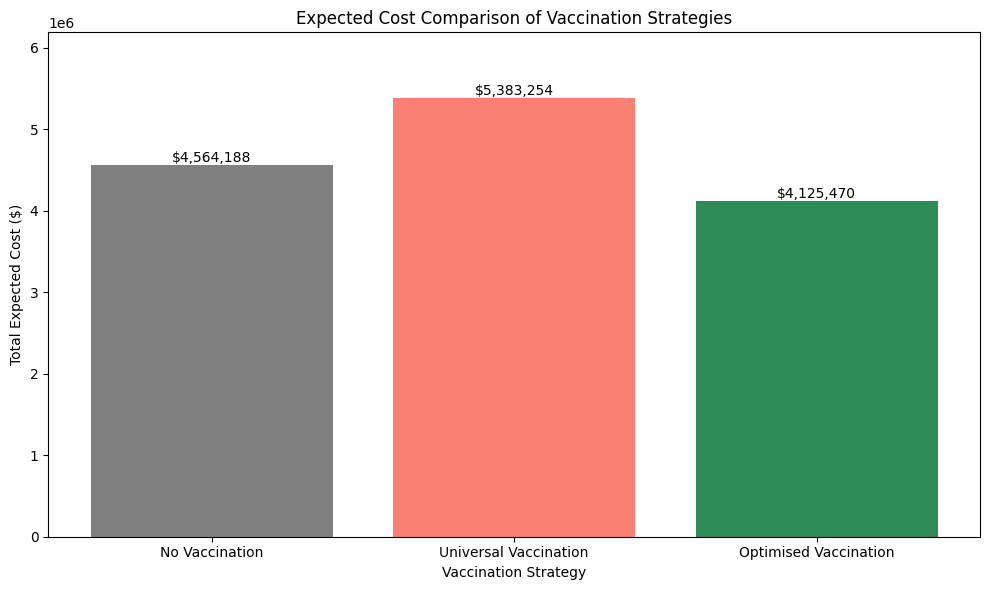

In [34]:
import matplotlib.pyplot as plt

strategies = [
    'No Vaccination',
    'Universal Vaccination',
    'Optimised Vaccination'
]

costs = [
    baseline_cost,
    universal_cost,
    optimal_cost
]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    strategies,
    costs,
    color=['gray', 'salmon', 'seagreen']
)

plt.title('Expected Cost Comparison of Vaccination Strategies')
plt.ylabel('Total Expected Cost ($)')
plt.xlabel('Vaccination Strategy')

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f'${height:,.0f}',
        ha='center',
        va='bottom'
    )

plt.ylim(0, max(costs) * 1.15)
plt.tight_layout()
plt.show()

**Validate the cost model using sensitivity analysis**

In [35]:
# Sensitivity analysis: vaccine effectiveness

import pandas as pd
import numpy as np

effectiveness_scenarios = [0.4, 0.6, 0.8, 1.0]

sensitivity_results = []

for effectiveness in effectiveness_scenarios:

    # Expected hospitalisation cost without vaccination
    no_offer = (
        risk_data['hospitalisation_risk'] * hospital_cost
    )

    # Expected cost when vaccination is offered
    offer = (
        vaccine_cost
        + no_offer * (
            1 - effectiveness
            * risk_data['acceptance_probability']
        )
    )

    # Select the lower-cost decision for each respondent
    optimal = np.minimum(no_offer, offer)

    savings = no_offer.sum() - optimal.sum()

    sensitivity_results.append({
        'Vaccine Effectiveness': f'{effectiveness:.0%}',
        'People Offered': int((offer < no_offer).sum()),
        'Optimal Cost ($)': optimal.sum(),
        'Expected Savings ($)': savings,
        'Cost Reduction (%)': (
            savings / no_offer.sum() * 100
        )
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df.round(2))

,Vaccine Effectiveness,People Offered,Optimal Cost ($),Expected Savings ($),Cost Reduction (%)
0,40%,324,4495117.20,69070.30,1.51
1,60%,671,4337207.37,226980.13,4.97
2,80%,1001,4125469.66,438717.84,9.61
3,100%,1272,3874042.17,690145.33,15.12


Submission 1 – Logistic Regression

In [36]:
# Step 12.2: Generate first submission

import pandas as pd

# Predict vaccination acceptance on the test dataset
final_predictions = logistic_model.predict(X_test)

# Create submission DataFrame
submission_1 = pd.DataFrame({
    'respondent_id': test['respondent_id'],
    'h1n1_vaccine': final_predictions.astype(int)
})

# Verify submission
print("Submission shape:", submission_1.shape)

print("\nPrediction distribution:")
print(submission_1['h1n1_vaccine'].value_counts())

print("\nMissing values:")
print(submission_1.isna().sum())

print("\nFirst five rows:")
display(submission_1.head())

# Save CSV file
submission_1.to_csv(
    'challenge_submission_group_X_order_1.csv',
    index=False
)

print("\nFirst submission file created successfully!")

Submission shape: (4749, 2)

Prediction distribution:
h1n1_vaccine
0    3102
1    1647
Name: count, dtype: int64

Missing values:
respondent_id    0
h1n1_vaccine     0
dtype: int64

First five rows:


,respondent_id,h1n1_vaccine
0,4757,0
1,4758,0
2,4759,0
3,4760,0
4,4761,0



First submission file created successfully!


Create Submission 2 using CatBoost

In [37]:
# Step 12.3: Generate CatBoost submission

# Predict vaccination acceptance
cat_predictions = catboost_model.predict(X_test)

# Create submission DataFrame
submission_2 = pd.DataFrame({
    'respondent_id': test['respondent_id'],
    'h1n1_vaccine': cat_predictions.astype(int)
})

# Validate submission
assert len(submission_2) == len(test)
assert submission_2['respondent_id'].equals(
    test['respondent_id']
)
assert submission_2['h1n1_vaccine'].isin([0, 1]).all()
assert submission_2.isna().sum().sum() == 0

print("Submission shape:", submission_2.shape)

print("\nPrediction distribution:")
print(submission_2['h1n1_vaccine'].value_counts())

print("\nMissing values:")
print(submission_2.isna().sum())

display(submission_2.head())

# Save CSV
submission_2.to_csv(
    'challenge_submission_group_X_order_2.csv',
    index=False
)

print("\nCatBoost submission created successfully!")

Submission shape: (4749, 2)

Prediction distribution:
h1n1_vaccine
0    3056
1    1693
Name: count, dtype: int64

Missing values:
respondent_id    0
h1n1_vaccine     0
dtype: int64


,respondent_id,h1n1_vaccine
0,4757,0
1,4758,0
2,4759,0
3,4760,0
4,4761,0



CatBoost submission created successfully!


Create Submission 3 using Random Forest

In [38]:
# Step 12.4: Generate Random Forest submission

# Predict vaccination acceptance
rf_predictions = random_forest_model.predict(X_test)

# Create submission DataFrame
submission_3 = pd.DataFrame({
    'respondent_id': test['respondent_id'],
    'h1n1_vaccine': rf_predictions.astype(int)
})

# Validate submission
assert submission_3.shape == (len(test), 2)

assert submission_3['respondent_id'].equals(
    test['respondent_id']
)

assert submission_3['h1n1_vaccine'].isin([0, 1]).all()

assert submission_3.isna().sum().sum() == 0

# Display results
print("Submission shape:", submission_3.shape)

print("\nPrediction distribution:")
print(submission_3['h1n1_vaccine'].value_counts())

print("\nMissing values:")
print(submission_3.isna().sum())

print("\nFirst five rows:")
display(submission_3.head())

# Save CSV file
submission_3.to_csv(
    'challenge_submission_group_X_order_3.csv',
    index=False
)

print("\nRandom Forest submission created successfully!")

Submission shape: (4749, 2)

Prediction distribution:
h1n1_vaccine
0    3227
1    1522
Name: count, dtype: int64

Missing values:
respondent_id    0
h1n1_vaccine     0
dtype: int64

First five rows:


,respondent_id,h1n1_vaccine
0,4757,0
1,4758,0
2,4759,0
3,4760,0
4,4761,0



Random Forest submission created successfully!


Build Submission 4 using an Ensemble Model

In [39]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import numpy as np

# Combine validation probabilities
ensemble_prob_valid = (
    y_prob_logistic +
    y_prob_rf +
    y_prob_catboost
) / 3

# Convert probabilities to binary predictions
ensemble_pred_valid = (
    ensemble_prob_valid >= 0.5
).astype(int)

# Evaluate ensemble
ensemble_accuracy = accuracy_score(
    y_valid, ensemble_pred_valid
)

ensemble_precision = precision_score(
    y_valid, ensemble_pred_valid
)

ensemble_recall = recall_score(
    y_valid, ensemble_pred_valid
)

ensemble_f1 = f1_score(
    y_valid, ensemble_pred_valid
)

ensemble_auc = roc_auc_score(
    y_valid, ensemble_prob_valid
)

print("Ensemble Model Performance")
print("--------------------------------")

print(f"Accuracy:  {ensemble_accuracy:.4f}")
print(f"Precision: {ensemble_precision:.4f}")
print(f"Recall:    {ensemble_recall:.4f}")
print(f"F1 Score:  {ensemble_f1:.4f}")
print(f"ROC-AUC:   {ensemble_auc:.4f}")

Ensemble Model Performance
--------------------------------
Accuracy:  0.7637
Precision: 0.7389
Recall:    0.6187
F1 Score:  0.6734
ROC-AUC:   0.8151


Submission 4 – Soft-Voting Ensemble

In [40]:
import numpy as np
import pandas as pd

# Generate test probabilities from all three models
lr_test_prob = logistic_model.predict_proba(X_test)[:, 1]

rf_test_prob = random_forest_model.predict_proba(X_test)[:, 1]

cat_test_prob = catboost_model.predict_proba(X_test)[:, 1]

# Calculate ensemble probabilities
ensemble_test_prob = (
    lr_test_prob +
    rf_test_prob +
    cat_test_prob
) / 3

# Convert probabilities into binary predictions
ensemble_test_predictions = (
    ensemble_test_prob >= 0.5
).astype(int)

# Create submission
submission_4 = pd.DataFrame({
    'respondent_id': test['respondent_id'],
    'h1n1_vaccine': ensemble_test_predictions
})

# Validate submission
assert submission_4.shape == (len(test), 2)
assert submission_4['respondent_id'].equals(test['respondent_id'])
assert submission_4['h1n1_vaccine'].isin([0, 1]).all()
assert submission_4.isna().sum().sum() == 0

print("Submission shape:", submission_4.shape)

print("\nPrediction distribution:")
print(submission_4['h1n1_vaccine'].value_counts())

print("\nMissing values:")
print(submission_4.isna().sum())

print("\nFirst five rows:")
display(submission_4.head())

# Save CSV
submission_4.to_csv(
    'challenge_submission_group_X_order_4.csv',
    index=False
)

print("\nEnsemble submission created successfully!")

Submission shape: (4749, 2)

Prediction distribution:
h1n1_vaccine
0    3123
1    1626
Name: count, dtype: int64

Missing values:
respondent_id    0
h1n1_vaccine     0
dtype: int64

First five rows:


,respondent_id,h1n1_vaccine
0,4757,0
1,4758,0
2,4759,0
3,4760,0
4,4761,0



Ensemble submission created successfully!


Find a cost-sensitive classification threshold

In [41]:
import numpy as np
import pandas as pd

# Build validation risk estimates using the same assumptions
valid_risk = X_valid['age_group'].map(age_risk)

valid_chronic = (
    X_valid['number_chronic_med_conditions']
    .fillna(0)
)

valid_risk = (
    valid_risk * (1 + 0.5 * valid_chronic)
).clip(upper=1.0)

assert valid_risk.notna().all()

# Evaluate different thresholds
threshold_results = []

for threshold in np.arange(0.20, 0.81, 0.05):

    predictions = (
        y_prob_logistic >= threshold
    ).astype(int)

    # Cost if no vaccine is offered
    no_offer_cost = valid_risk * hospital_cost

    # Cost if vaccination is offered:
    # Actual acceptance is represented by y_valid
    offer_cost = (
        vaccine_cost
        + no_offer_cost
        * (1 - vaccine_effectiveness * y_valid)
    )

    # Use predicted acceptance to decide who receives an offer
    total_cost = np.where(
        predictions == 1,
        offer_cost,
        no_offer_cost
    ).sum()

    threshold_results.append({
        'Threshold': round(threshold, 2),
        'Predicted Acceptances': int(predictions.sum()),
        'Estimated Total Cost': total_cost
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.sort_values('Estimated Total Cost')
    .round(2)
)

,Threshold,Predicted Acceptances,Estimated Total Cost
8,0.60,270,889750.0
9,0.65,223,889950.0
6,0.50,321,891550.0
7,0.55,295,892500.0
10,0.70,191,894200.0
5,0.45,360,899700.0
12,0.80,121,902250.0
11,0.75,150,902850.0
4,0.40,403,904300.0
3,0.35,448,915100.0


Generate Submission 5 using threshold 0.60

In [42]:
# Step 12.8: Generate Submission 5

import numpy as np
import pandas as pd

# Selected threshold from validation analysis
best_threshold = 0.60

# Predict vaccination acceptance probabilities
test_probabilities = logistic_model.predict_proba(
    X_test
)[:, 1]

# Apply cost-sensitive threshold
threshold_predictions = (
    test_probabilities >= best_threshold
).astype(int)

# Create submission
submission_5 = pd.DataFrame({
    'respondent_id': test['respondent_id'],
    'h1n1_vaccine': threshold_predictions
})

# Validate submission
assert submission_5.shape == (len(test), 2)

assert submission_5['respondent_id'].equals(
    test['respondent_id']
)

assert submission_5['h1n1_vaccine'].isin([0, 1]).all()

assert submission_5.isna().sum().sum() == 0

# Display results
print("Submission shape:", submission_5.shape)

print("\nPrediction distribution:")
print(submission_5['h1n1_vaccine'].value_counts())

print("\nMissing values:")
print(submission_5.isna().sum())

print("\nFirst five rows:")
display(submission_5.head())

# Save CSV
submission_5.to_csv(
    'challenge_submission_group_X_order_5.csv',
    index=False
)

print("\nSubmission 5 created successfully!")

Submission shape: (4749, 2)

Prediction distribution:
h1n1_vaccine
0    3448
1    1301
Name: count, dtype: int64

Missing values:
respondent_id    0
h1n1_vaccine     0
dtype: int64

First five rows:


,respondent_id,h1n1_vaccine
0,4757,0
1,4758,0
2,4759,0
3,4760,0
4,4761,0



Submission 5 created successfully!


**Final submission validation**

In [43]:
# Step 13.1: Validate all five submissions

submissions = {
    "Logistic Regression": submission_1,
    "CatBoost": submission_2,
    "Random Forest": submission_3,
    "Ensemble": submission_4,
    "Threshold 0.60": submission_5
}

expected_columns = [
    'respondent_id',
    'h1n1_vaccine'
]

for name, df in submissions.items():

    assert list(df.columns) == expected_columns

    assert len(df) == len(test)

    assert df['respondent_id'].is_unique

    assert df['respondent_id'].equals(
        test['respondent_id']
    )

    assert df['h1n1_vaccine'].isin([0, 1]).all()

    assert df.isna().sum().sum() == 0

    print(f"{name}: PASSED")

print("\nAll five submissions validated successfully!")

Logistic Regression: PASSED
CatBoost: PASSED
Random Forest: PASSED
Ensemble: PASSED
Threshold 0.60: PASSED

All five submissions validated successfully!


Compare all five models using the cost metric

In [44]:
# Step 13.2: Compare all five models by estimated cost

import numpy as np
import pandas as pd

# Validation predictions
model_predictions = {
    "Logistic Regression": logistic_model.predict(X_valid),
    "CatBoost": catboost_model.predict(X_valid),
    "Random Forest": random_forest_model.predict(X_valid),
    "Ensemble": ensemble_pred_valid,
    "Threshold 0.60": (
        y_prob_logistic >= 0.60
    ).astype(int)
}

# Align observed vaccination outcomes with validation rows
actual_acceptance = np.asarray(y_valid)

# Use the hospitalisation risk estimates from Step 12.7
baseline_cost_per_person = (
    np.asarray(valid_risk) * hospital_cost
)

results = []

for name, predictions in model_predictions.items():

    predictions = np.asarray(predictions).astype(int)

    # Actual vaccination acceptance determines
    # whether an offer reduces hospitalisation risk
    offer_cost = (
        vaccine_cost
        + baseline_cost_per_person
        * (1 - vaccine_effectiveness * actual_acceptance)
    )

    total_cost = np.where(
        predictions == 1,
        offer_cost,
        baseline_cost_per_person
    ).sum()

    results.append({
        "Model": name,
        "Predicted Acceptances": predictions.sum(),
        "Estimated Total Cost ($)": total_cost
    })

cost_comparison = pd.DataFrame(results)

cost_comparison = cost_comparison.sort_values(
    "Estimated Total Cost ($)"
).reset_index(drop=True)

display(cost_comparison.round(2))

,Model,Predicted Acceptances,Estimated Total Cost ($)
0,Threshold 0.60,270,889750.0
1,Ensemble,314,889900.0
2,Logistic Regression,321,891550.0
3,Random Forest,305,893500.0
4,CatBoost,341,896700.0


Rename the five submission files in the new ranking

In [45]:
# Step 13.3: Reorder submissions by estimated cost

group_number = "X"  # Replace X with your group number

ranked_submissions = [
    submission_5,  # Rank 1: Threshold 0.60
    submission_4,  # Rank 2: Ensemble
    submission_1,  # Rank 3: Logistic Regression
    submission_3,  # Rank 4: Random Forest
    submission_2   # Rank 5: CatBoost
]

for rank, submission in enumerate(
    ranked_submissions, start=1
):
    filename = (
        f"challenge_submission_group_"
        f"{group_number}_order_{rank}.csv"
    )

    submission.to_csv(filename, index=False)

    print(f"Created: {filename}")

print("\nAll five ranked submissions saved!")

Created: challenge_submission_group_X_order_1.csv
Created: challenge_submission_group_X_order_2.csv
Created: challenge_submission_group_X_order_3.csv
Created: challenge_submission_group_X_order_4.csv
Created: challenge_submission_group_X_order_5.csv

All five ranked submissions saved!


Rename and download your five CSV files

In [46]:
import zipfile
from google.colab import files

# Replace X with your actual group number
group_number = "G"

zip_filename = f"hackathon_group_{group_number}_submissions.zip"

with zipfile.ZipFile(zip_filename, 'w') as zipf:

    for rank, submission in enumerate(
        ranked_submissions, start=1
    ):
        filename = (
            f"challenge_submission_group_"
            f"{group_number}_order_{rank}.csv"
        )

        submission.to_csv(filename, index=False)
        zipf.write(filename)

        print(f"Added: {filename}")

print("\nZIP file created successfully!")

# Download ZIP file
files.download(zip_filename)

Added: challenge_submission_group_G_order_1.csv
Added: challenge_submission_group_G_order_2.csv
Added: challenge_submission_group_G_order_3.csv
Added: challenge_submission_group_G_order_4.csv
Added: challenge_submission_group_G_order_5.csv

ZIP file created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>